# 14-Channel WL1/WL2 Signal Analysis

This notebook validates and analyzes the 14-channel patient CSV sampled at 400 Hz. All calculations use the full-resolution data; only dense visualizations are thinned for display.

## Configuration

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal

DATA_DIR = Path("data")
FS_HZ = 400
SIGNAL_BAND_HZ = (1.9, 2.7)
OUTPUT_DIR = Path("analysis_outputs")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})

## Phase 1 — Load and validate

In [ ]:
if not isinstance(FS_HZ, (int, float)) or FS_HZ <= 0:
    raise ValueError(f"FS_HZ must be positive, got {FS_HZ!r}")

csv_files = sorted(DATA_DIR.glob("*.csv"))
if len(csv_files) != 1:
    raise FileNotFoundError(
        f"Expected exactly one CSV in {DATA_DIR}, found {len(csv_files)}: "
        f"{[path.name for path in csv_files]}"
    )

expected_columns = [
    f"ch{channel}voltsWL{wavelength}"
    for wavelength in (1, 2)
    for channel in range(1, 8)
]
raw = pd.read_csv(csv_files[0])
missing_columns = sorted(set(expected_columns) - set(raw.columns))
unexpected_columns = sorted(set(raw.columns) - set(expected_columns))
if missing_columns or unexpected_columns:
    raise ValueError(
        f"Unexpected CSV schema. Missing: {missing_columns or 'none'}; "
        f"unexpected: {unexpected_columns or 'none'}"
    )

data = raw[expected_columns].apply(pd.to_numeric, errors="coerce")
nonnumeric = data.isna() & raw[expected_columns].notna()
if nonnumeric.any().any():
    locations = {column: int(nonnumeric[column].sum()) for column in expected_columns if nonnumeric[column].any()}
    raise ValueError(f"Nonnumeric values found: {locations}")
if data.isna().any().any():
    missing = {column: int(data[column].isna().sum()) for column in expected_columns if data[column].isna().any()}
    raise ValueError(f"Missing values found: {missing}")
if not np.isfinite(data.to_numpy()).all():
    raise ValueError("Infinite values found in channel data")
if data.empty:
    raise ValueError("The CSV contains no samples")

time_s = np.arange(len(data)) / FS_HZ
duration_min = len(data) / FS_HZ / 60
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert len(data.columns) == 14
assert np.isclose(duration_min, 19.98, atol=0.02), f"Unexpected duration: {duration_min:.3f} minutes"
print(f"Loaded {csv_files[0].name}")
print(f"Samples: {len(data):,} | Channels: {len(data.columns)} | Duration: {duration_min:.3f} min")

Loaded 730nm@100mW_850nm@100mW_450hz_330hz_50%_f1_WL1WL2_demod_downsampAVG_400Hz.csv
Samples: 479,601 | Channels: 14 | Duration: 19.983 min


## Phase 2 — Time-domain analysis

In [ ]:
summary = data.agg(["mean", "std", "min", "max"]).T
summary["rms"] = np.sqrt(data.pow(2).mean())
summary["peak_to_peak"] = summary["max"] - summary["min"]
summary["missing_count"] = data.isna().sum().astype(int)
summary = summary[["mean", "std", "rms", "min", "max", "peak_to_peak", "missing_count"]]
summary.index.name = "channel"
summary.to_csv(OUTPUT_DIR / "channel_summary.csv")
summary

,mean,std,rms,min,max,peak_to_peak,missing_count
channel,,,,,,,
ch1voltsWL1,0.411791,0.020783,0.412315,8.096000e-02,0.520760,0.439800,0
ch2voltsWL1,0.217974,0.013083,0.218367,4.703000e-02,0.276660,0.229630,0
ch3voltsWL1,0.110783,0.008115,0.111080,2.468800e-02,0.142230,0.117542,0
ch4voltsWL1,0.281079,0.028465,0.282517,6.539100e-02,0.382630,0.317239,0
ch5voltsWL1,0.028327,0.002595,0.028445,6.469600e-03,0.038180,0.031710,0
ch6voltsWL1,0.051149,0.024749,0.056822,4.336700e-12,0.100660,0.100660,0
ch7voltsWL1,0.009600,0.001313,0.009689,2.323200e-03,0.013884,0.011561,0
ch1voltsWL2,0.479630,0.028294,0.480464,1.850500e-01,0.648510,0.463460,0
ch2voltsWL2,0.178041,0.013921,0.178585,8.061200e-02,0.275320,0.194708,0


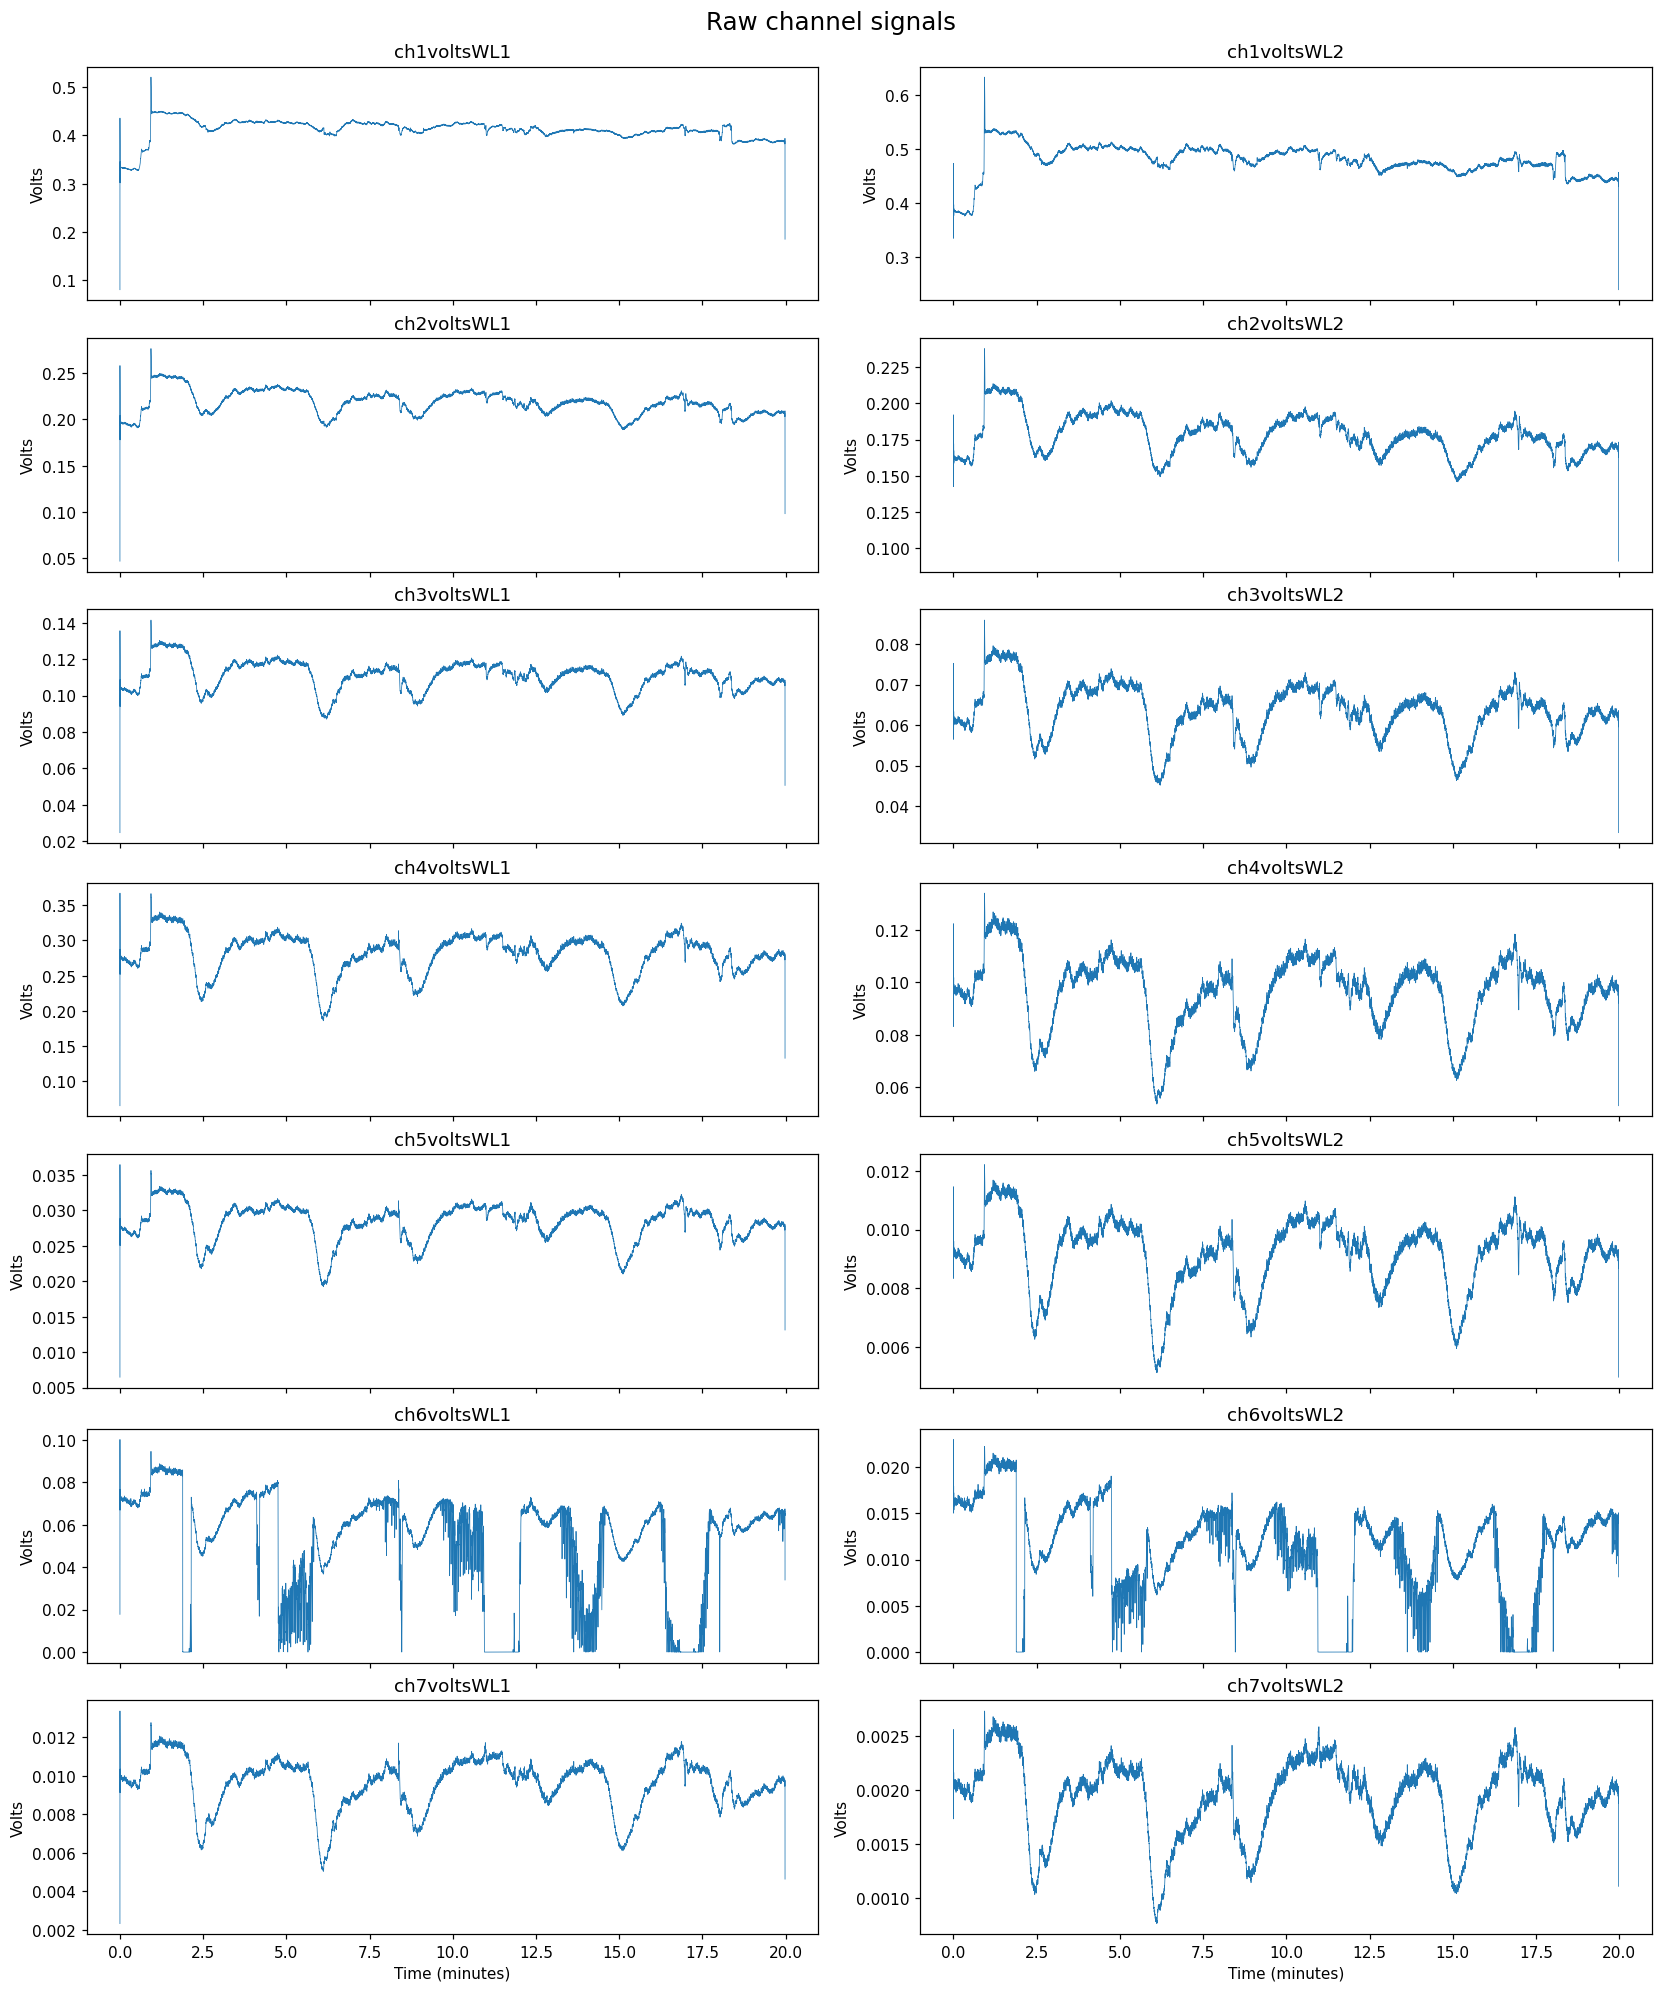

In [18]:
plot_step = max(1, len(data) // 25_000)
fig, axes = plt.subplots(7, 2, figsize=(15, 18), sharex=True, constrained_layout=True)
for wavelength in (1, 2):
    for channel in range(1, 8):
        column = f"ch{channel}voltsWL{wavelength}"
        ax = axes[channel - 1, wavelength - 1]
        ax.plot(time_s[::plot_step] / 60, data[column].to_numpy()[::plot_step], linewidth=0.5)
        ax.set_title(column)
        ax.set_ylabel("Volts")
for ax in axes[-1]:
    ax.set_xlabel("Time (minutes)")
fig.suptitle("Raw channel signals", fontsize=16)
fig.savefig(OUTPUT_DIR / "raw_time_traces.png", bbox_inches="tight")
plt.show()

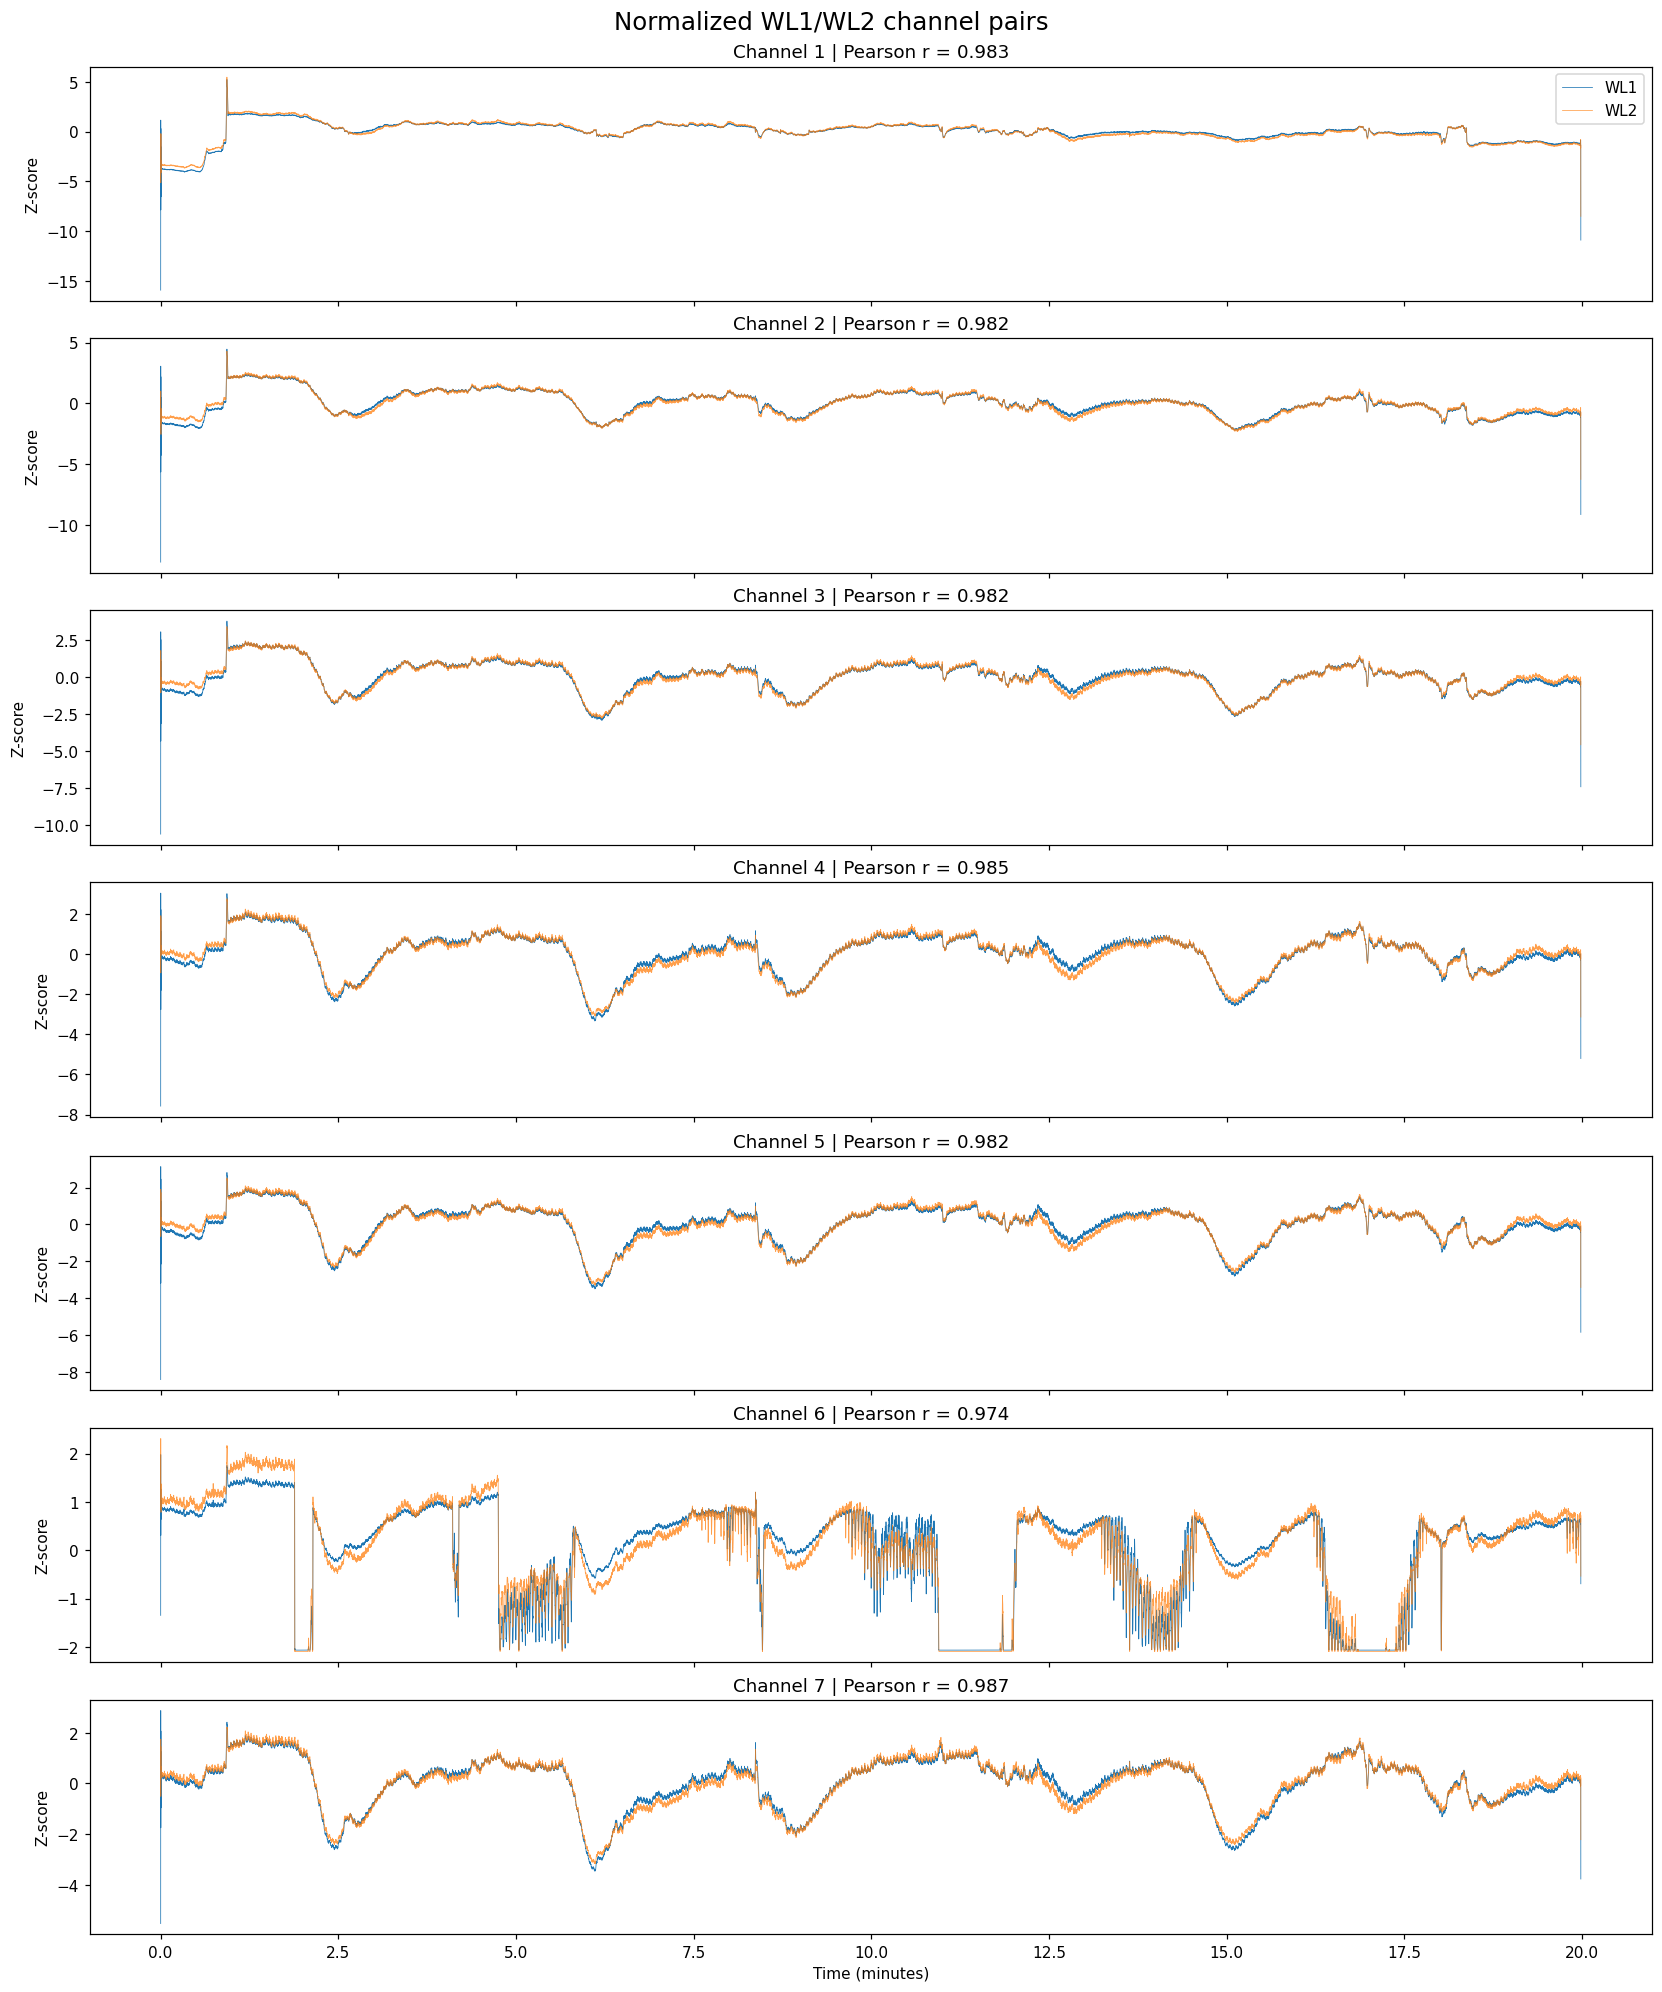

,pearson_correlation
channel,
1,0.982659
2,0.981809
3,0.982331
4,0.984592
5,0.982340
6,0.973670
7,0.986658


In [19]:
pair_rows = []
fig, axes = plt.subplots(7, 1, figsize=(15, 18), sharex=True, constrained_layout=True)
for channel, ax in enumerate(axes, start=1):
    wl1 = data[f"ch{channel}voltsWL1"]
    wl2 = data[f"ch{channel}voltsWL2"]
    if wl1.std(ddof=0) == 0 or wl2.std(ddof=0) == 0:
        raise ValueError(f"Channel {channel} is constant and cannot be normalized")
    wl1_z = (wl1 - wl1.mean()) / wl1.std(ddof=0)
    wl2_z = (wl2 - wl2.mean()) / wl2.std(ddof=0)
    correlation = wl1.corr(wl2)
    pair_rows.append({"channel": channel, "pearson_correlation": correlation})
    ax.plot(time_s[::plot_step] / 60, wl1_z.to_numpy()[::plot_step], linewidth=0.5, label="WL1")
    ax.plot(time_s[::plot_step] / 60, wl2_z.to_numpy()[::plot_step], linewidth=0.5, alpha=0.75, label="WL2")
    ax.set_title(f"Channel {channel} | Pearson r = {correlation:.3f}")
    ax.set_ylabel("Z-score")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Time (minutes)")
fig.suptitle("Normalized WL1/WL2 channel pairs", fontsize=16)
fig.savefig(OUTPUT_DIR / "normalized_wavelength_pairs.png", bbox_inches="tight")
plt.show()

pair_correlations = pd.DataFrame(pair_rows).set_index("channel")
pair_correlations.to_csv(OUTPUT_DIR / "wavelength_pair_correlations.csv")
pair_correlations

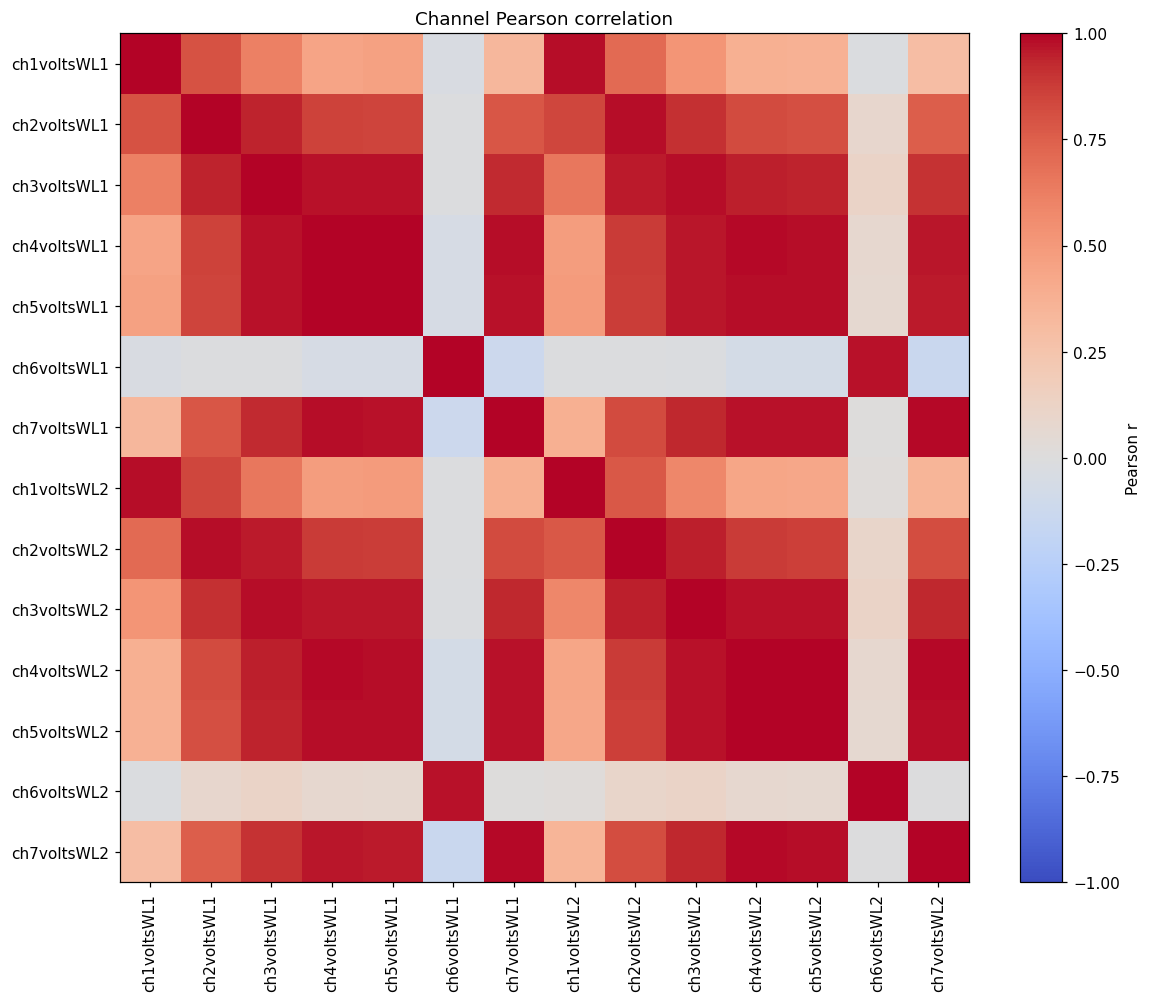

In [20]:
correlation = data.corr()
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(14))
ax.set_xticklabels(correlation.columns, rotation=90)
ax.set_yticks(range(14))
ax.set_yticklabels(correlation.index)
ax.set_title("Channel Pearson correlation")
fig.colorbar(image, ax=ax, label="Pearson r")
fig.savefig(OUTPUT_DIR / "channel_correlation.png", bbox_inches="tight")
plt.show()

## Phase 3 — Frequency analysis

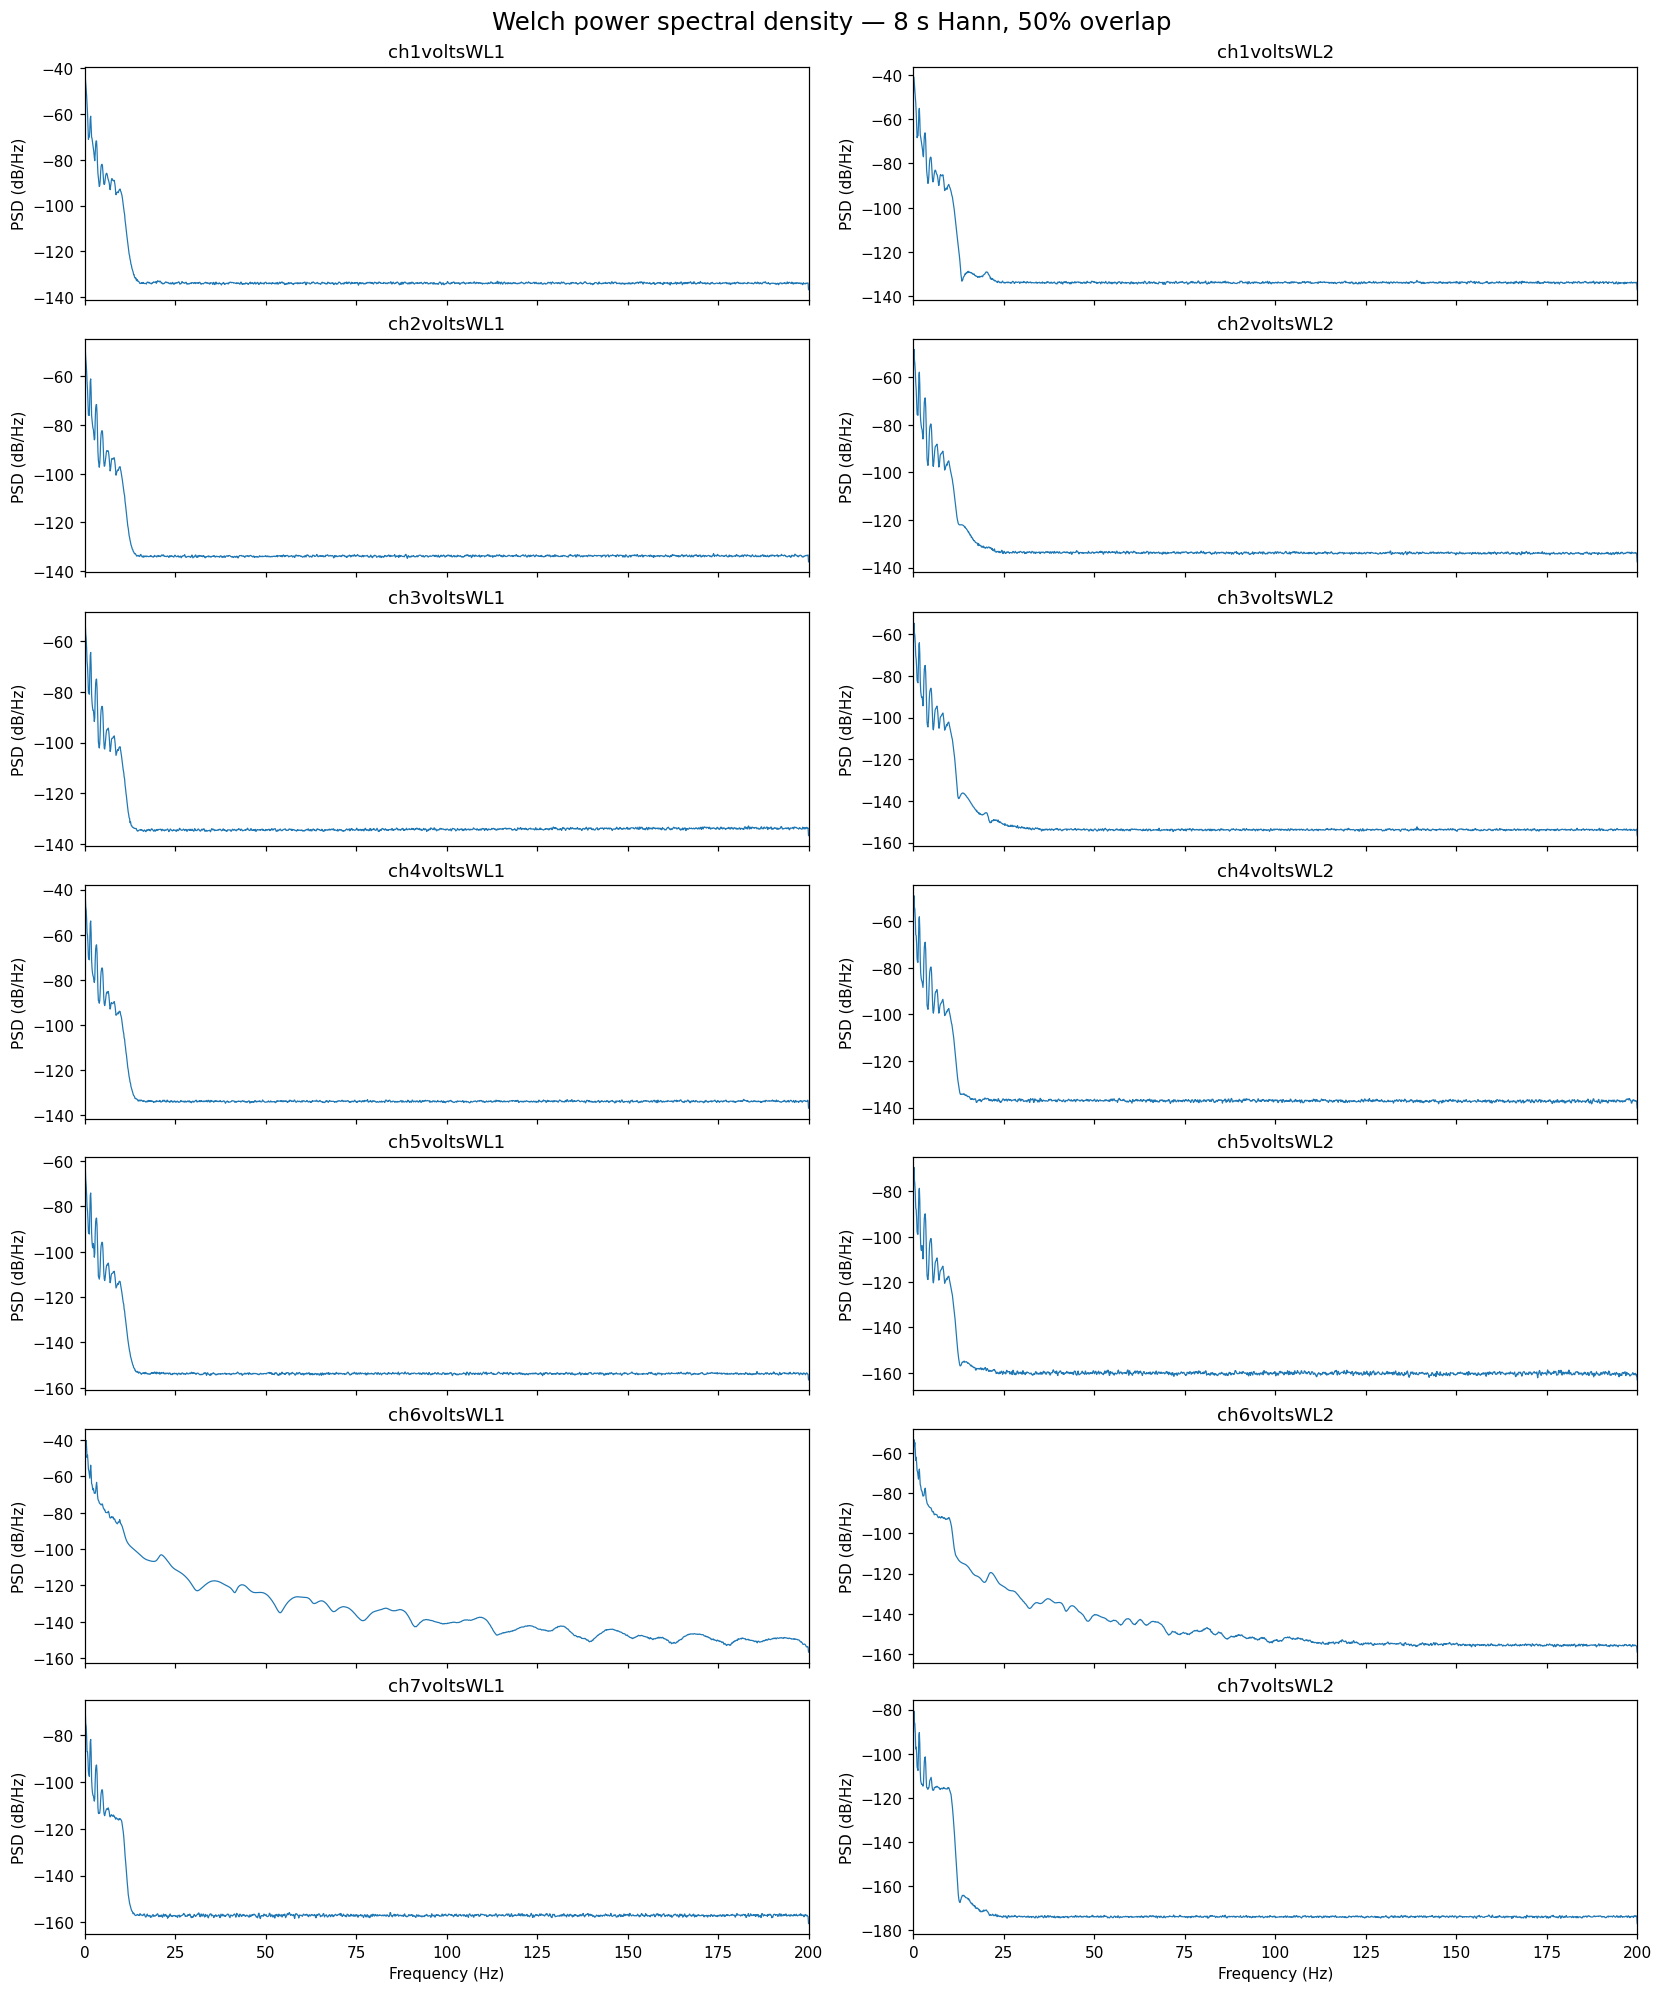

In [21]:
welch_nperseg = int(8 * FS_HZ)
fig, axes = plt.subplots(7, 2, figsize=(15, 18), sharex=True, constrained_layout=True)
for wavelength in (1, 2):
    for channel in range(1, 8):
        column = f"ch{channel}voltsWL{wavelength}"
        frequencies, psd = signal.welch(
            data[column].to_numpy(),
            fs=FS_HZ,
            window="hann",
            nperseg=welch_nperseg,
            noverlap=welch_nperseg // 2,
            detrend="constant",
            scaling="density",
        )
        if not np.isfinite(psd).all():
            raise ValueError(f"Non-finite PSD generated for {column}")
        ax = axes[channel - 1, wavelength - 1]
        ax.plot(frequencies, 10 * np.log10(np.maximum(psd, np.finfo(float).tiny)), linewidth=0.8)
        ax.set_title(column)
        ax.set_ylabel("PSD (dB/Hz)")
        ax.set_xlim(0, FS_HZ / 2)
for ax in axes[-1]:
    ax.set_xlabel("Frequency (Hz)")
fig.suptitle("Welch power spectral density — 8 s Hann, 50% overlap", fontsize=16)
fig.savefig(OUTPUT_DIR / "welch_psd.png", bbox_inches="tight")
plt.show()

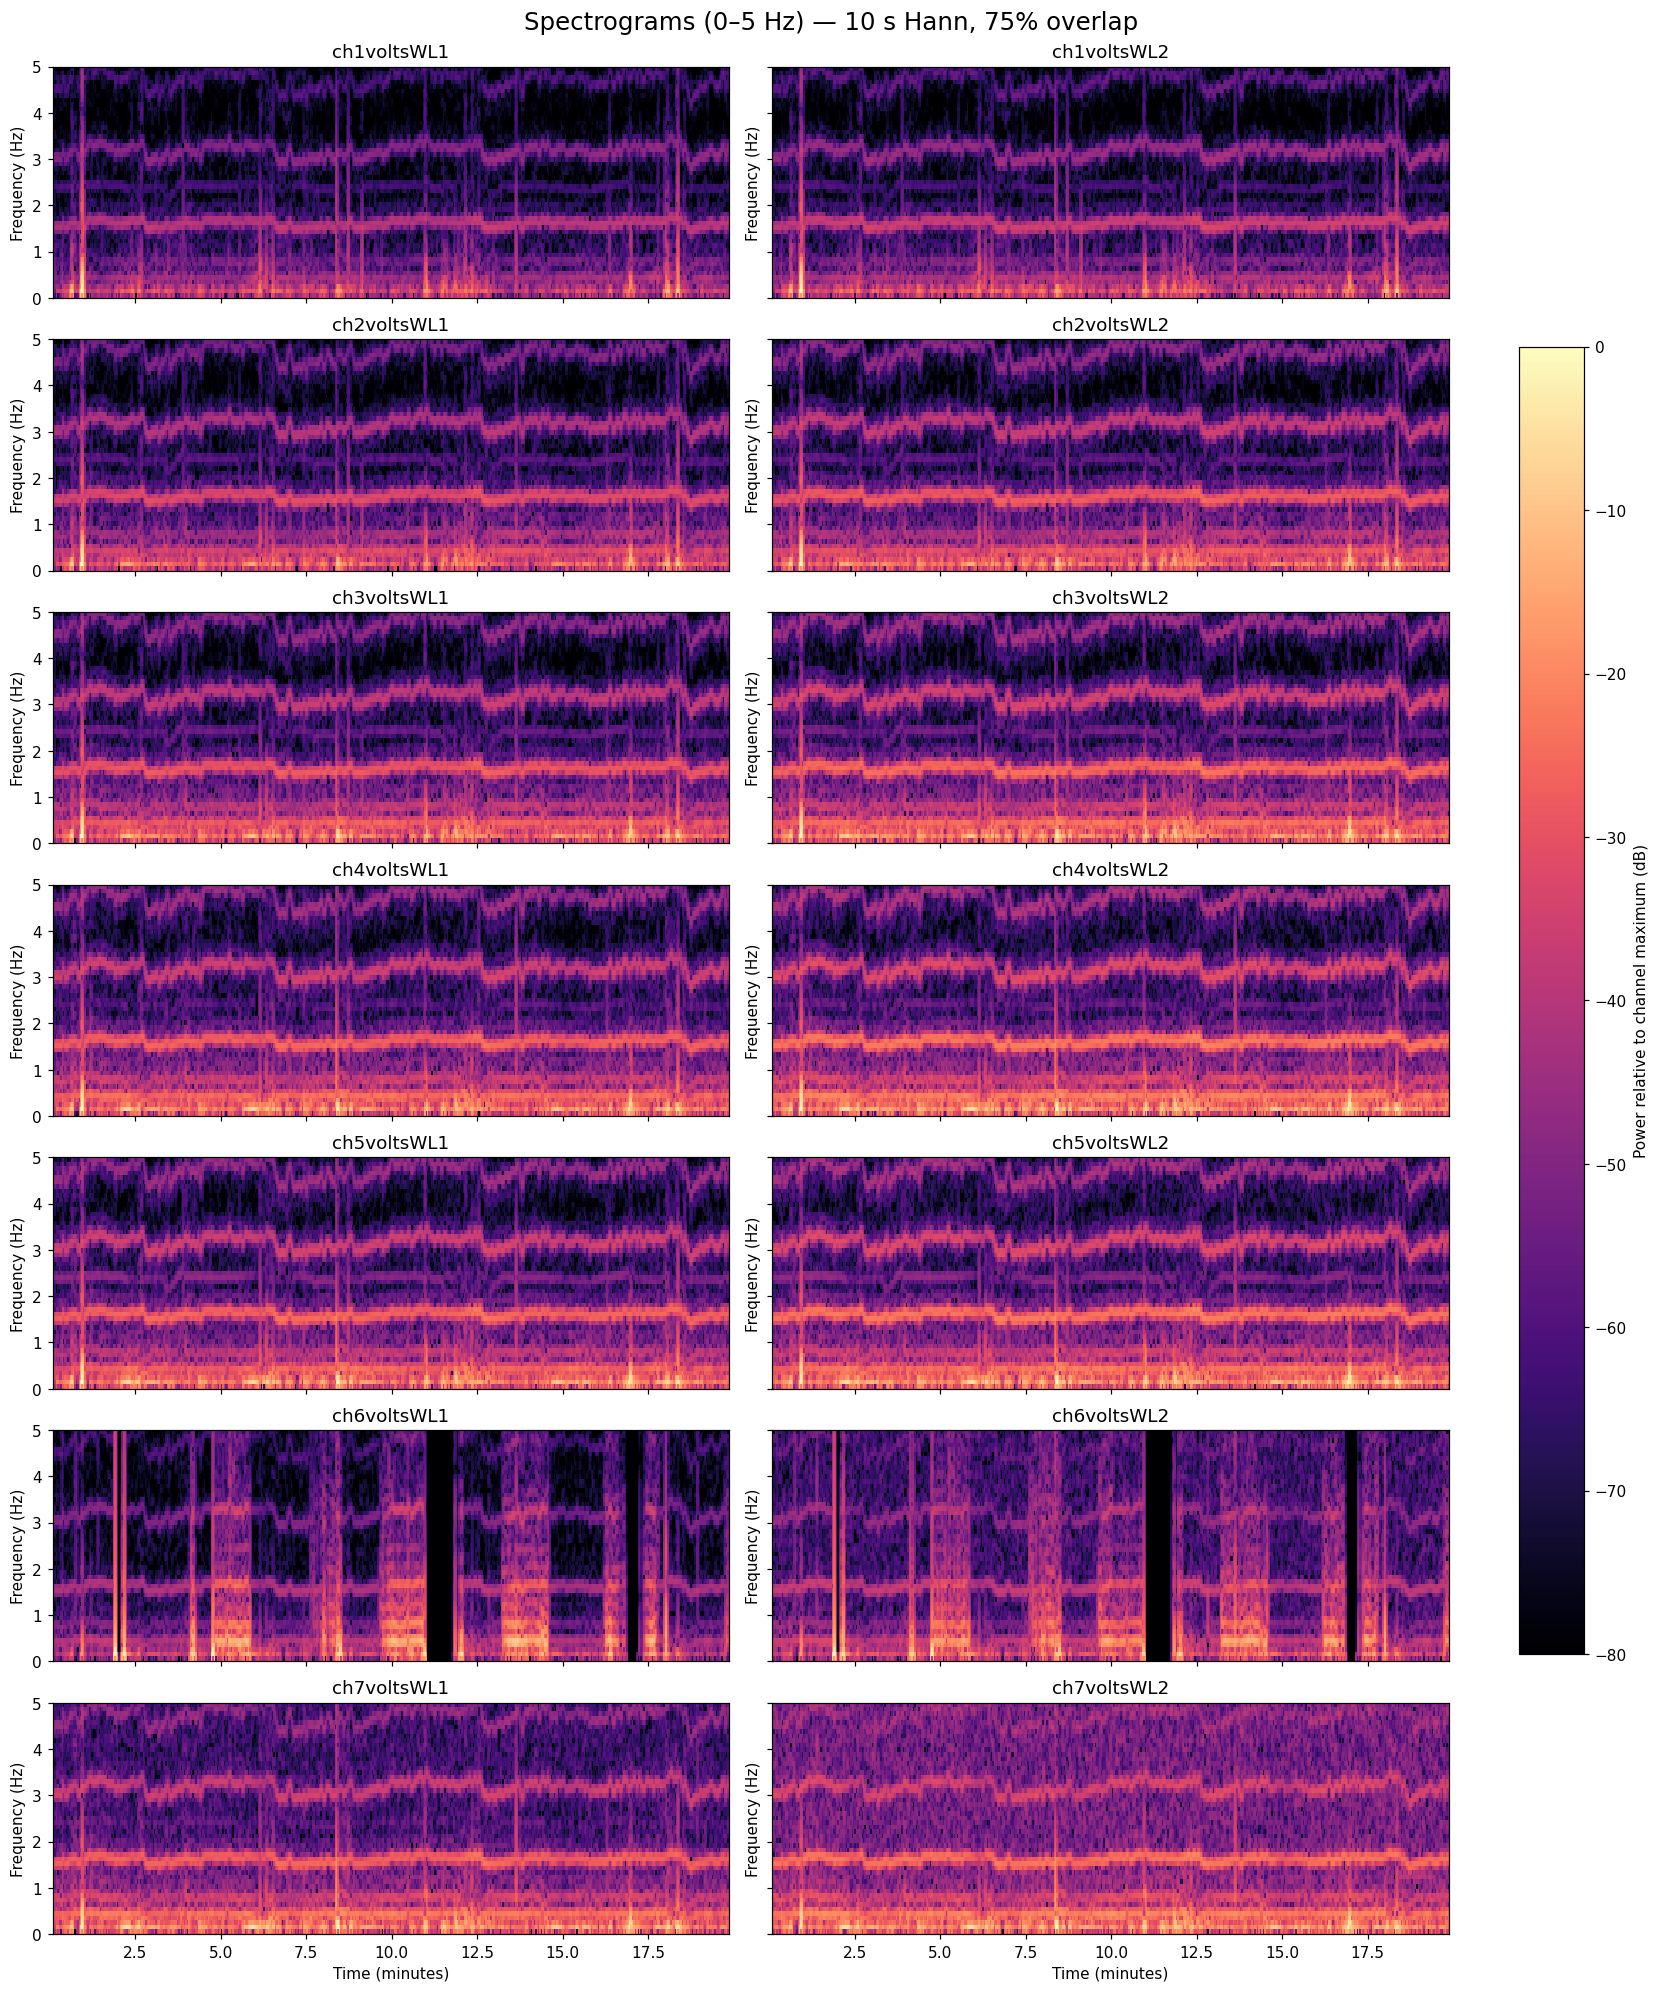

In [22]:
spectrogram_nperseg = int(10 * FS_HZ)
fig, axes = plt.subplots(7, 2, figsize=(15, 18), sharex=True, sharey=True, constrained_layout=True)
for wavelength in (1, 2):
    for channel in range(1, 8):
        column = f"ch{channel}voltsWL{wavelength}"
        frequencies, times, spectrum = signal.spectrogram(
            data[column].to_numpy(),
            fs=FS_HZ,
            window="hann",
            nperseg=spectrogram_nperseg,
            noverlap=int(0.75 * spectrogram_nperseg),
            detrend="constant",
            scaling="density",
            mode="psd",
        )
        if not np.isfinite(spectrum).all():
            raise ValueError(f"Non-finite spectrogram generated for {column}")
        spectrum_db = 10 * np.log10(np.maximum(spectrum, np.finfo(float).tiny))
        spectrum_db -= spectrum_db.max()
        frequency_mask = frequencies <= 5
        ax = axes[channel - 1, wavelength - 1]
        image = ax.imshow(
            spectrum_db[frequency_mask],
            origin="lower",
            aspect="auto",
            extent=[times[0] / 60, times[-1] / 60, frequencies[0], frequencies[frequency_mask][-1]],
            vmin=-80,
            vmax=0,
            cmap="magma",
            interpolation="nearest",
        )
        ax.set_title(column)
        ax.set_ylabel("Frequency (Hz)")
        ax.set_ylim(0, 5)
for ax in axes[-1]:
    ax.set_xlabel("Time (minutes)")
fig.colorbar(image, ax=axes, label="Power relative to channel maximum (dB)", shrink=0.7)
fig.suptitle("Spectrograms (0–5 Hz) — 10 s Hann, 75% overlap", fontsize=16)
fig.savefig(OUTPUT_DIR / "spectrograms.png", bbox_inches="tight")
plt.show()

## Phase 4 ? Extract the 2.5 Hz signal

In [23]:
low_hz, high_hz = SIGNAL_BAND_HZ
if not 0 < low_hz < high_hz < FS_HZ / 2:
    raise ValueError(f"SIGNAL_BAND_HZ must lie inside (0, {FS_HZ / 2:g}), got {SIGNAL_BAND_HZ}")

bandpass_sos = signal.butter(
    4,
    SIGNAL_BAND_HZ,
    btype="bandpass",
    fs=FS_HZ,
    output="sos",
)

# Small runnable check: preserve 2.5 Hz and strongly reject a 10 Hz interferer.
test_time = np.arange(30 * FS_HZ) / FS_HZ
test_reference = np.sin(2 * np.pi * 2.5 * test_time)
test_interference = np.sin(2 * np.pi * 10 * test_time)
test_filtered = signal.sosfiltfilt(bandpass_sos, test_reference + test_interference)
interference_filtered = signal.sosfiltfilt(bandpass_sos, test_interference)
test_valid = slice(5 * FS_HZ, -5 * FS_HZ)
preservation = np.corrcoef(test_reference[test_valid], test_filtered[test_valid])[0, 1]
rejection_db = 20 * np.log10(
    np.std(test_interference[test_valid])
    / np.maximum(np.std(interference_filtered[test_valid]), np.finfo(float).tiny)
)
assert preservation > 0.99, f"2.5 Hz preservation check failed: r={preservation:.4f}"
assert rejection_db > 40, f"10 Hz rejection check failed: {rejection_db:.1f} dB"
print(f"Filter check passed: 2.5 Hz r={preservation:.4f}, 10 Hz rejection={rejection_db:.1f} dB")

Filter check passed: 2.5 Hz r=1.0000, 10 Hz rejection=79.1 dB


In [24]:
edge_samples = int(10 * FS_HZ)
if len(data) <= 2 * edge_samples:
    raise ValueError("Recording must be longer than the two 10-second filter-edge regions")

extracted = pd.DataFrame(
    {
        column: signal.sosfiltfilt(bandpass_sos, data[column].to_numpy())
        for column in expected_columns
    }
)
envelopes = pd.DataFrame(
    {
        column: np.abs(signal.hilbert(extracted[column].to_numpy()))
        for column in expected_columns
    }
)

valid = slice(edge_samples, len(data) - edge_samples)
extraction_rows = []
for column in expected_columns:
    frequencies, psd = signal.welch(
        data[column].to_numpy(),
        fs=FS_HZ,
        window="hann",
        nperseg=int(8 * FS_HZ),
        noverlap=int(4 * FS_HZ),
        detrend="constant",
        scaling="density",
    )
    target = (frequencies >= low_hz) & (frequencies <= high_hz)
    adjacent = ((frequencies >= 2.0) & (frequencies < low_hz)) | (
        (frequencies > high_hz) & (frequencies <= 3.0)
    )
    filtered_valid = extracted[column].to_numpy()[valid]
    envelope_valid = envelopes[column].to_numpy()[valid]
    extraction_rows.append(
        {
            "channel": column,
            "filtered_rms": np.sqrt(np.mean(filtered_valid**2)),
            "median_envelope": np.median(envelope_valid),
            "p95_envelope": np.percentile(envelope_valid, 95),
            "target_band_contrast_db": 10 * np.log10(
                np.mean(psd[target]) / np.maximum(np.mean(psd[adjacent]), np.finfo(float).tiny)
            ),
        }
    )

extraction_summary = pd.DataFrame(extraction_rows).set_index("channel")
extraction_summary.to_csv(OUTPUT_DIR / "2p5hz_extraction_summary.csv")
extraction_summary

,filtered_rms,median_envelope,p95_envelope,target_band_contrast_db
channel,,,,
ch1voltsWL1,0.000165,0.000052,0.000151,2.194468
ch2voltsWL1,0.000070,0.000036,0.000088,-4.575856
ch3voltsWL1,0.000036,0.000023,0.000053,-6.987987
ch4voltsWL1,0.000110,0.000061,0.000162,-8.026512
ch5voltsWL1,0.000011,0.000009,0.000018,-7.534192
ch6voltsWL1,0.000395,0.000037,0.000871,2.158228
ch7voltsWL1,0.000005,0.000003,0.000008,-7.399799
ch1voltsWL2,0.000226,0.000074,0.000205,-0.167923
ch2voltsWL2,0.000069,0.000038,0.000088,-7.442832


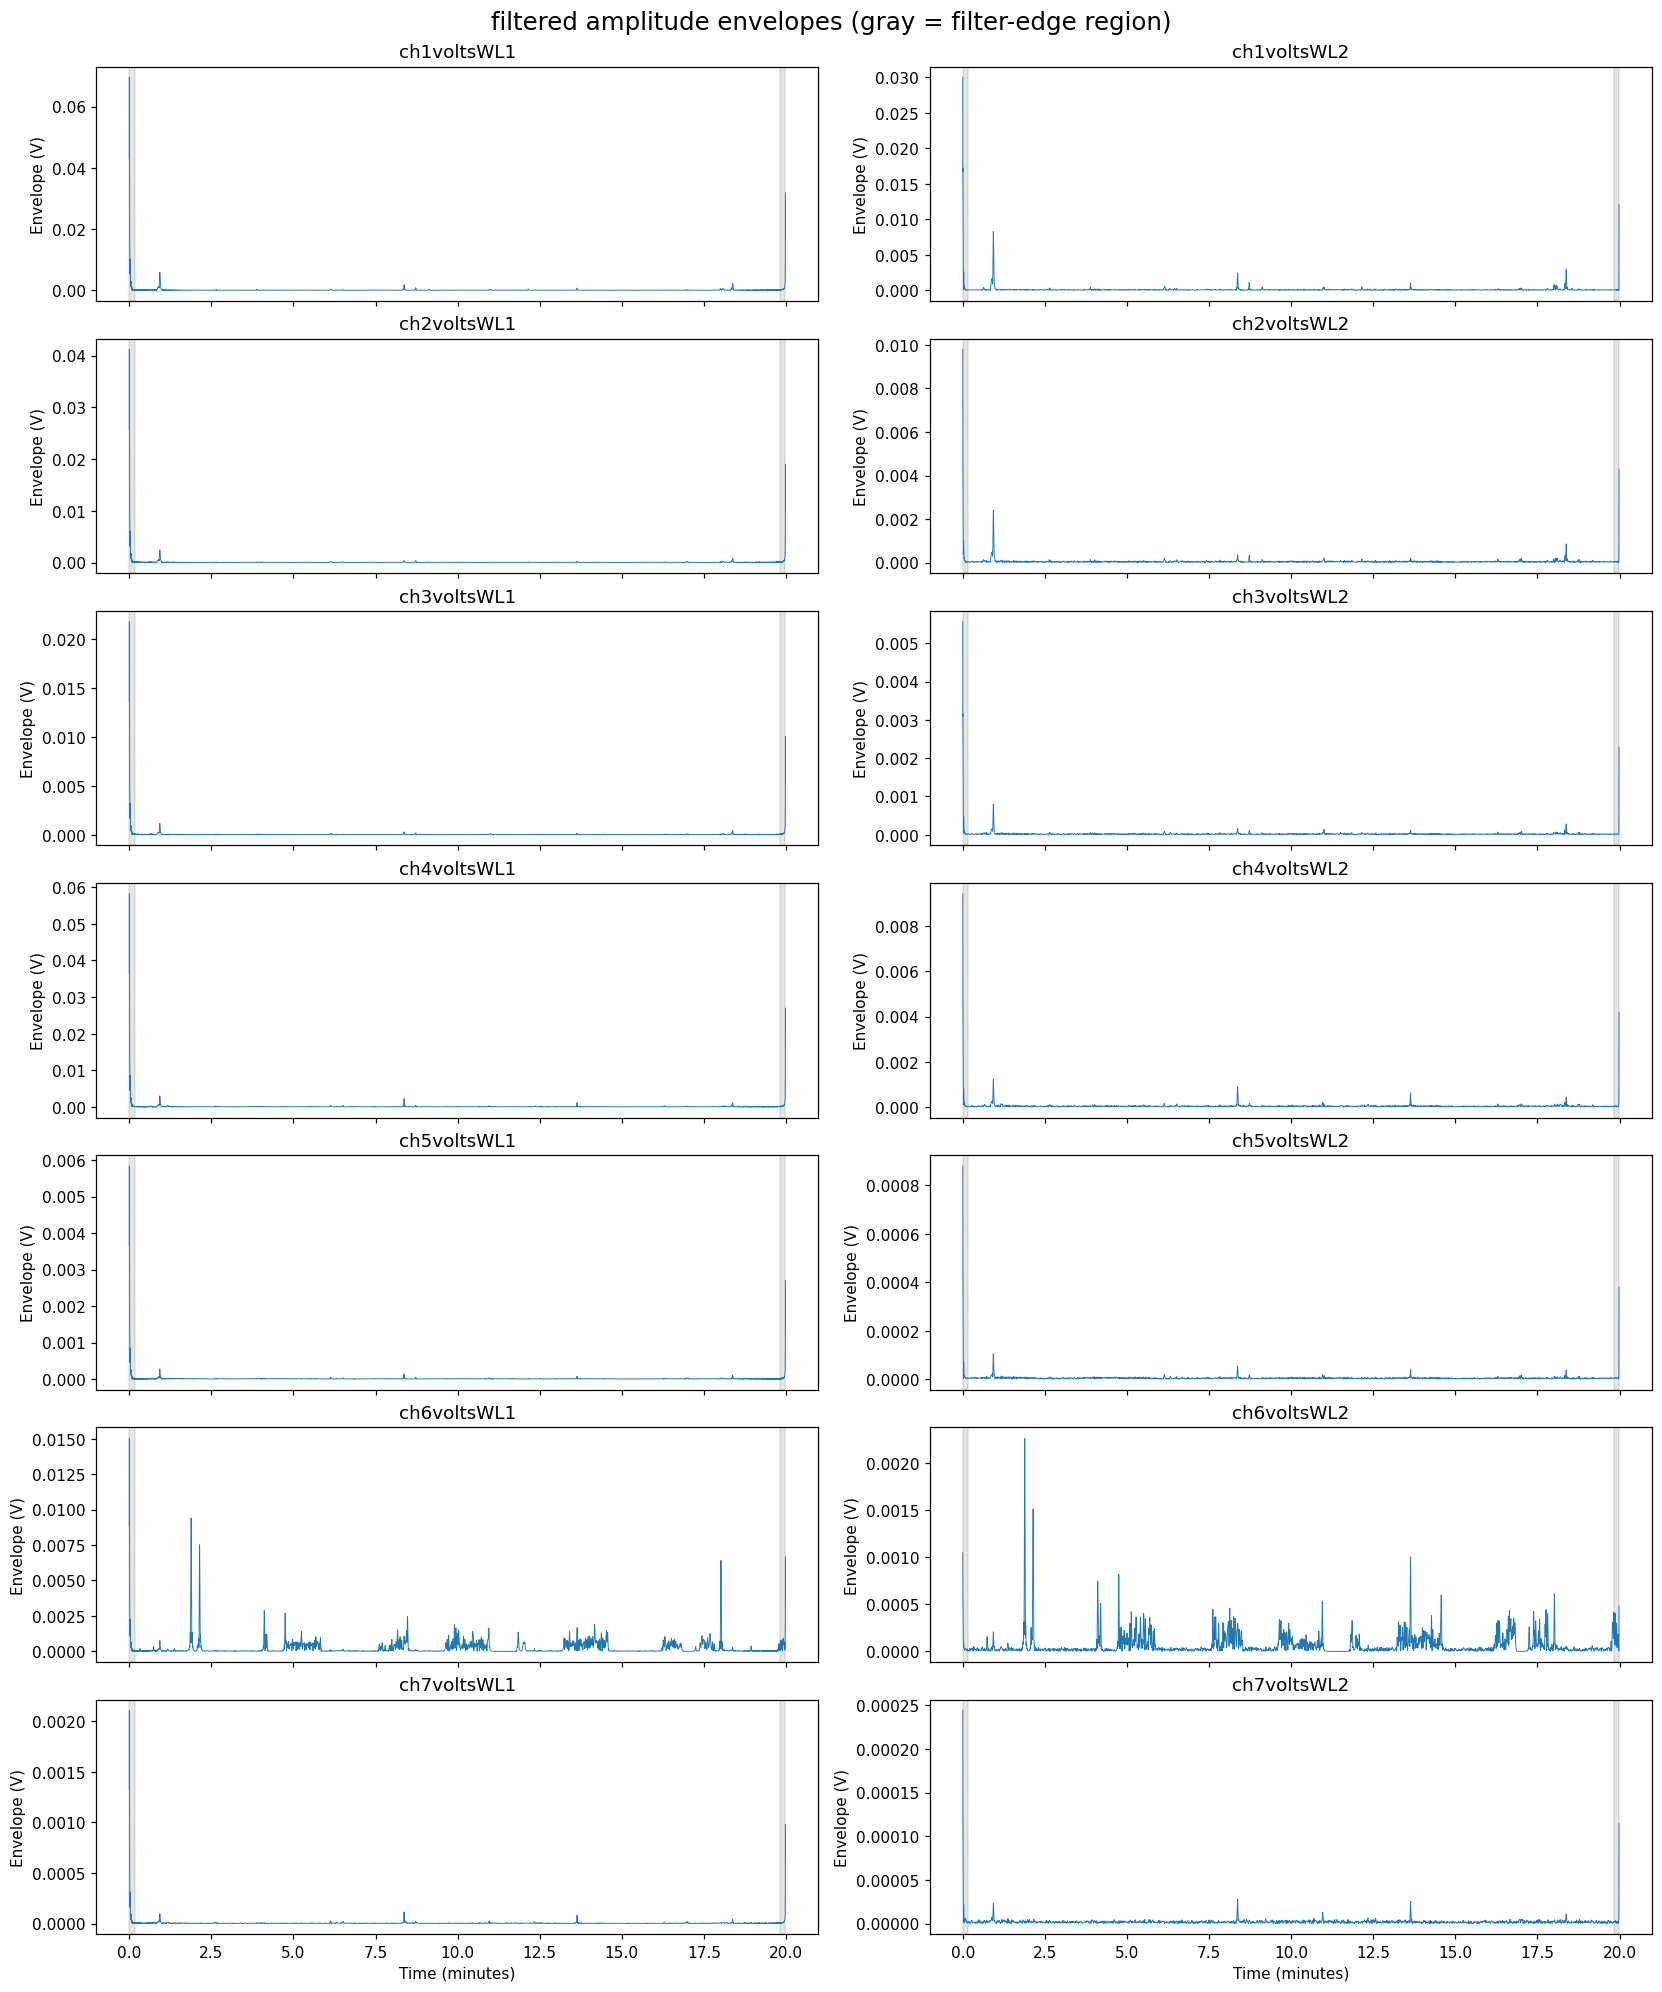

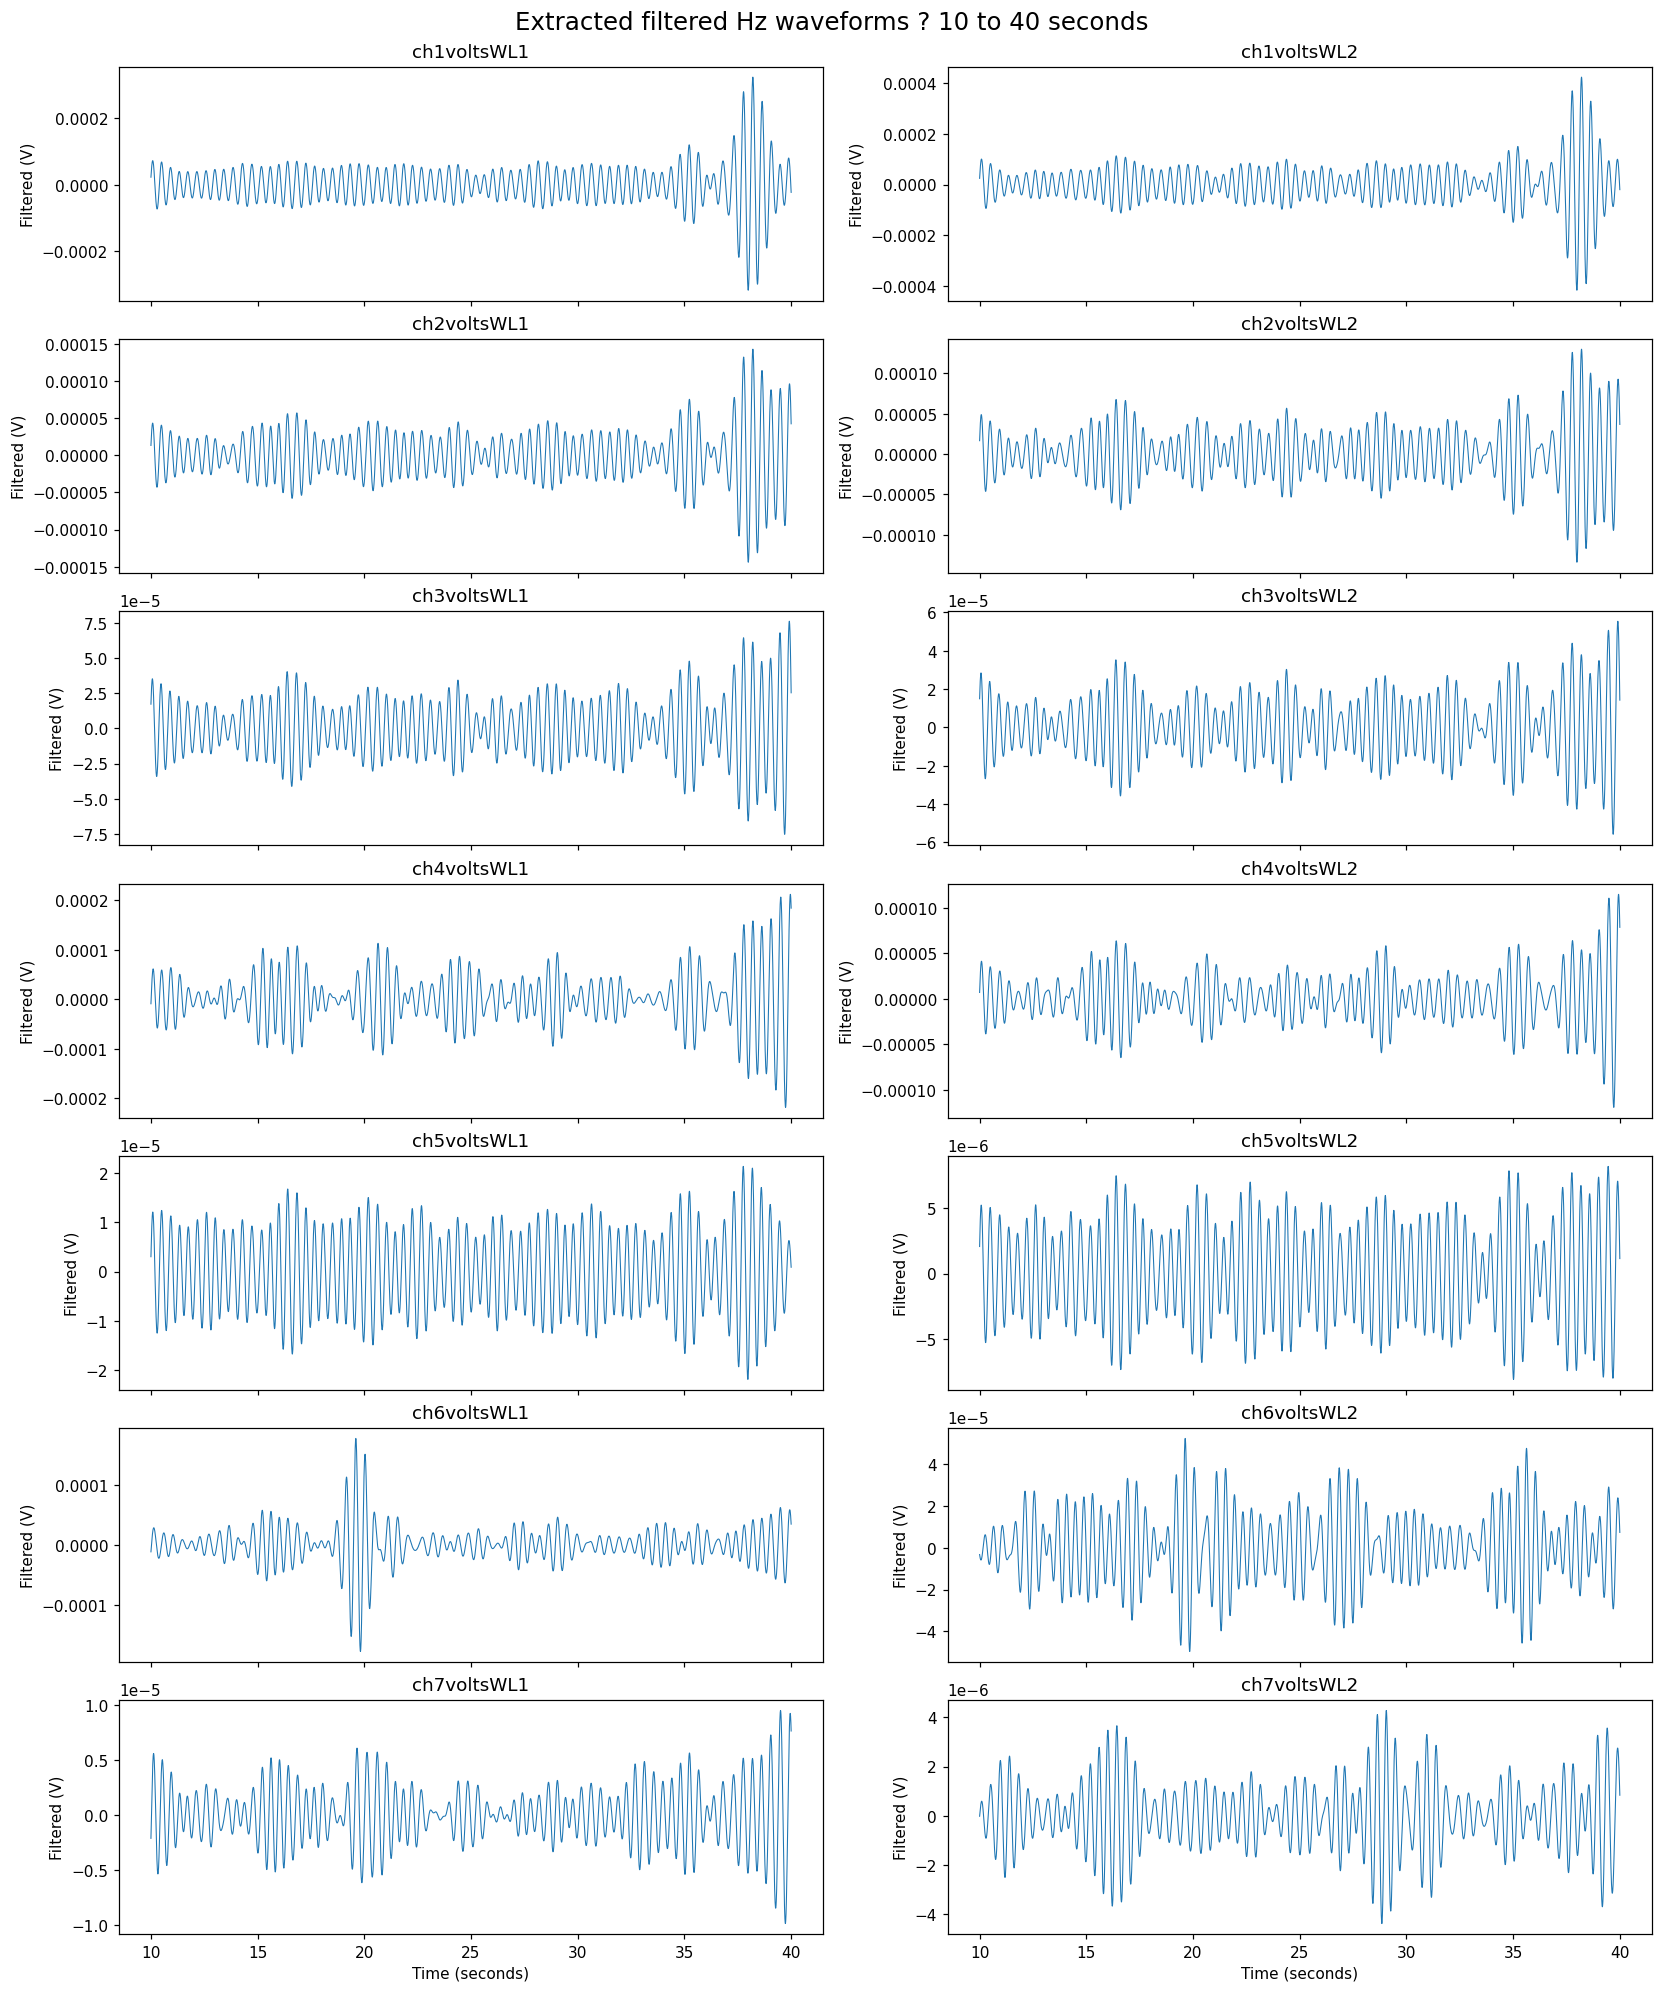

In [29]:
fig, axes = plt.subplots(7, 2, figsize=(15, 18), sharex=True, constrained_layout=True)
for wavelength in (1, 2):
    for channel in range(1, 8):
        column = f"ch{channel}voltsWL{wavelength}"
        ax = axes[channel - 1, wavelength - 1]
        ax.plot(time_s[::plot_step] / 60, envelopes[column].to_numpy()[::plot_step], linewidth=0.6)
        ax.axvspan(0, 10 / 60, color="gray", alpha=0.2)
        ax.axvspan((time_s[-1] - 10) / 60, time_s[-1] / 60, color="gray", alpha=0.2)
        ax.set_title(column)
        ax.set_ylabel("Envelope (V)")
for ax in axes[-1]:
    ax.set_xlabel("Time (minutes)")
fig.suptitle("filtered amplitude envelopes (gray = filter-edge region)", fontsize=16)
fig.savefig(OUTPUT_DIR / "2p5hz_envelopes.png", bbox_inches="tight")
plt.show()

detail_mask = (time_s >= 10) & (time_s < 40)
fig, axes = plt.subplots(7, 2, figsize=(15, 18), sharex=True, constrained_layout=True)
for wavelength in (1, 2):
    for channel in range(1, 8):
        column = f"ch{channel}voltsWL{wavelength}"
        ax = axes[channel - 1, wavelength - 1]
        ax.plot(time_s[detail_mask], extracted.loc[detail_mask, column], linewidth=0.7)
        ax.set_title(column)
        ax.set_ylabel("Filtered (V)")
for ax in axes[-1]:
    ax.set_xlabel("Time (seconds)")
fig.suptitle("Extracted filtered Hz waveforms ? 10 to 40 seconds", fontsize=16)
fig.savefig(OUTPUT_DIR / "extracted_2p5hz_waveforms.png", bbox_inches="tight")
plt.show()

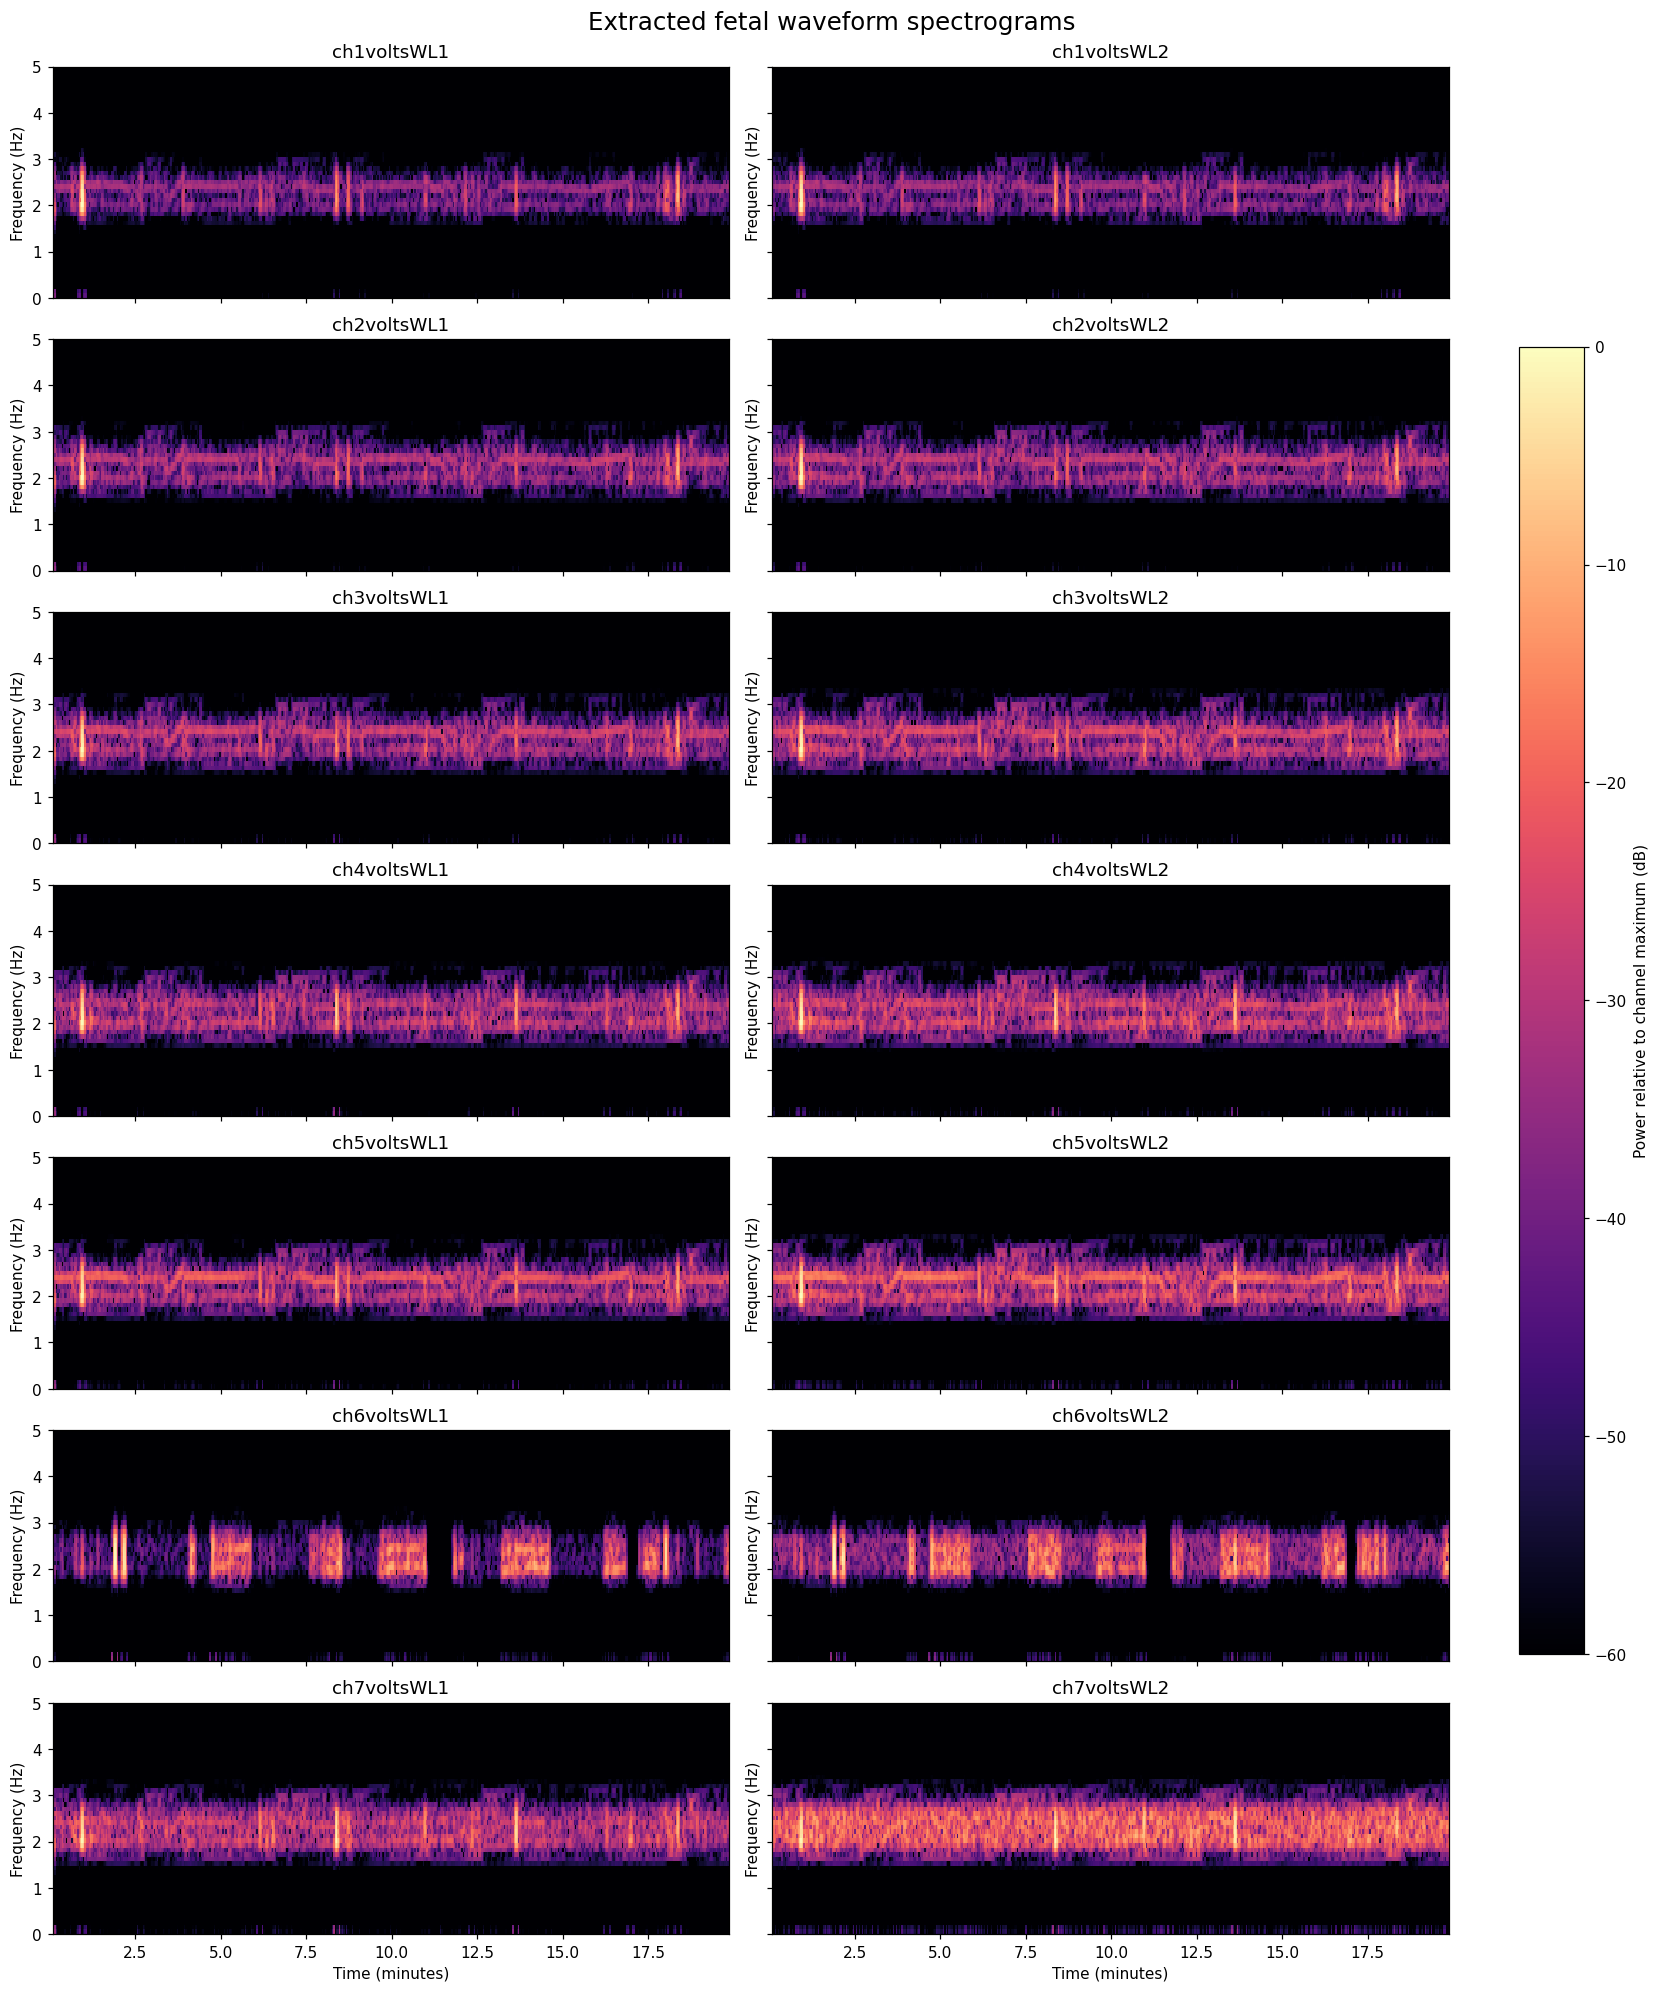

In [30]:
fig, axes = plt.subplots(7, 2, figsize=(15, 18), sharex=True, sharey=True, constrained_layout=True)
for wavelength in (1, 2):
    for channel in range(1, 8):
        column = f"ch{channel}voltsWL{wavelength}"
        frequencies, times, spectrum = signal.spectrogram(
            extracted[column].to_numpy(),
            fs=FS_HZ,
            window="hann",
            nperseg=int(10 * FS_HZ),
            noverlap=int(0.75 * 10 * FS_HZ),
            detrend="constant",
            scaling="density",
            mode="psd",
        )
        spectrum_db = 10 * np.log10(np.maximum(spectrum, np.finfo(float).tiny))
        spectrum_db -= spectrum_db.max()
        frequency_mask = frequencies <= 5
        ax = axes[channel - 1, wavelength - 1]
        image = ax.imshow(
            spectrum_db[frequency_mask],
            origin="lower",
            aspect="auto",
            extent=[times[0] / 60, times[-1] / 60, frequencies[0], frequencies[frequency_mask][-1]],
            vmin=-60,
            vmax=0,
            cmap="magma",
            interpolation="nearest",
        )
        ax.set_title(column)
        ax.set_ylabel("Frequency (Hz)")
        ax.set_ylim(0, 5)
for ax in axes[-1]:
    ax.set_xlabel("Time (minutes)")
fig.colorbar(image, ax=axes, label="Power relative to channel maximum (dB)", shrink=0.7)
fig.suptitle("Extracted fetal waveform spectrograms", fontsize=16)
fig.savefig(OUTPUT_DIR / "extracted_2p5hz_spectrograms.png", bbox_inches="tight")
plt.show()

In [27]:
waveform_export = extracted.copy()
waveform_export.insert(0, "time_s", time_s)
envelope_export = envelopes.copy()
envelope_export.insert(0, "time_s", time_s)

waveform_path = OUTPUT_DIR / "extracted_2p5hz_waveforms.csv"
envelope_path = OUTPUT_DIR / "extracted_2p5hz_envelopes.csv"
waveform_export.to_csv(waveform_path, index=False, float_format="%.9g")
envelope_export.to_csv(envelope_path, index=False, float_format="%.9g")
print(f"Saved {waveform_path} ({waveform_path.stat().st_size / 1e6:.1f} MB)")
print(f"Saved {envelope_path} ({envelope_path.stat().st_size / 1e6:.1f} MB)")

Saved analysis_outputs\extracted_2p5hz_waveforms.csv (107.8 MB)
Saved analysis_outputs\extracted_2p5hz_envelopes.csv (104.4 MB)


## Phase 5 ? Verify outputs

In [28]:
expected_outputs = [
    "channel_summary.csv",
    "wavelength_pair_correlations.csv",
    "raw_time_traces.png",
    "normalized_wavelength_pairs.png",
    "channel_correlation.png",
    "welch_psd.png",
    "spectrograms.png",
    "extracted_2p5hz_waveforms.csv",
    "extracted_2p5hz_envelopes.csv",
    "2p5hz_extraction_summary.csv",
    "extracted_2p5hz_waveforms.png",
    "extracted_2p5hz_spectrograms.png",
    "2p5hz_envelopes.png",
]
assert summary.shape == (14, 7)
assert pair_correlations.shape == (7, 1)
assert np.isfinite(summary.select_dtypes(include="number").to_numpy()).all()
assert np.isfinite(pair_correlations.to_numpy()).all()
assert extracted.shape == data.shape
assert envelopes.shape == data.shape
assert extraction_summary.shape == (14, 4)
assert np.isfinite(extracted.to_numpy()).all()
assert np.isfinite(envelopes.to_numpy()).all()
assert np.isfinite(extraction_summary.to_numpy()).all()
assert np.all(np.diff(time_s) > 0)
assert np.allclose(np.diff(time_s), 1 / FS_HZ, rtol=0, atol=1e-12)
for csv_path in (waveform_path, envelope_path):
    assert len(pd.read_csv(csv_path, nrows=0).columns) == 15
    with csv_path.open("r", encoding="utf-8") as handle:
        assert sum(1 for _ in handle) - 1 == len(data)
missing_outputs = [name for name in expected_outputs if not (OUTPUT_DIR / name).is_file()]
assert not missing_outputs, f"Missing outputs: {missing_outputs}"
print(f"Verification passed: 14 channel summaries, 7 wavelength pairs, 14 extractions, {len(expected_outputs)} output files.")

Verification passed: 14 channel summaries, 7 wavelength pairs, 14 extractions, 13 output files.
